## Library importing

In [2]:
import pandas as pd
from ydata_profiling import ProfileReport
import streamlit as st
from itables import show
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
%matplotlib inline


# Initial exploratory data analysis based on latest league-KEEPERS

An initial exploratory data analysis was performed on the dataset from a single league to determine the structure of the data, identify what information could be extracted, and understand how the data should be cleaned for further analysis.

## Data importing

In [3]:
keepers_currency_raw = pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/currency_data_raw/keepers.currency.csv", sep=";", low_memory=False)
keepers_items_raw = pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/items_data_raw/keepers.items.csv", sep=";", low_memory=False)


## Initial Data visualisation

In [4]:
keepers_currency_raw

,League,Date,Get,Pay,Value,Confidence
0,Keepers,2025-10-31,Chromatic Orb,Chaos Orb,0.20000,High
1,Keepers,2025-11-01,Chromatic Orb,Chaos Orb,0.19231,High
2,Keepers,2025-11-02,Chromatic Orb,Chaos Orb,0.19231,High
3,Keepers,2025-11-03,Chromatic Orb,Chaos Orb,0.16667,High
4,Keepers,2025-11-04,Chromatic Orb,Chaos Orb,0.14970,High
...,...,...,...,...,...,...
32296,Keepers,2025-12-03,Chayula's Flawless Breachstone,Chaos Orb,1370.70000,Low
32297,Keepers,2025-12-04,Chayula's Flawless Breachstone,Chaos Orb,1424.70000,Low
32298,Keepers,2025-12-05,Chayula's Flawless Breachstone,Chaos Orb,1476.00000,Low
32299,Keepers,2025-12-06,Chayula's Flawless Breachstone,Chaos Orb,1513.79991,Low


In [5]:
keepers_items_raw

,League,Date,Id,Type,Name,BaseType,Variant,Links,Value,Confidence
0,Keepers,2025-10-31,1034,UniqueWeapon,Redbeak,Rusted Sword,NaN,1-4 links,0.935,High
1,Keepers,2025-11-01,1034,UniqueWeapon,Redbeak,Rusted Sword,NaN,1-4 links,0.300,High
2,Keepers,2025-11-02,1034,UniqueWeapon,Redbeak,Rusted Sword,NaN,1-4 links,0.120,High
3,Keepers,2025-11-03,1034,UniqueWeapon,Redbeak,Rusted Sword,NaN,1-4 links,0.180,High
4,Keepers,2025-11-04,1034,UniqueWeapon,Redbeak,Rusted Sword,NaN,1-4 links,1.000,High
...,...,...,...,...,...,...,...,...,...,...
3572713,Keepers,2026-03-02,59926,BaseType,Assassin's Mitts,Assassin's Mitts,Shaper/Elder,NaN,3714.000,Low
3572714,Keepers,2026-03-02,66179,BaseType,Astral Plate,Astral Plate,Shaper/Hunter,NaN,742.800,Low
3572715,Keepers,2026-03-02,95517,BaseType,Sacrificial Garb,Sacrificial Garb,Redeemer/Hunter,NaN,1864.500,Low
3572716,Keepers,2026-03-02,134925,BaseType,Wraith Sword,Wraith Sword,Shaper/Redeemer,NaN,18720.000,Low


## Initial Exploratory Data Analysis

In [6]:

keepers_currency_raw_report = ProfileReport(keepers_currency_raw, title="Keepers Currency Profiling Report")
keepers_currency_raw_report

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 6/6 [00:00<00:00, 88.23it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

1. Alert: 
    > Value is highly skewed (γ₁ = 20.58)  

    Based on the knowledge of the game, this is not a data quality issue but a characteristic of the in-game currency system. Some types of currency drop extremely rarely and therefore have very high value. In contrast, most currencies are relatively common and drop in large quantities, resulting in very low market value. As a consequence, the distribution of currency values is strongly right-skewed, with a small number of very rare currencies forming a long right tail.

2. Generated profiling report shows other very important information that multiple currencies appear in the **Pay** column indicating that the dataset represents a general exchange network rather than a system with a single reference currency.Thus this issue has to be resolved in the data prepation section. 

In [7]:
keepers_items_raw_report = ProfileReport(keepers_items_raw, title="Keepers Items Profiling Report")
keepers_items_raw_report

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 10/10 [00:19<00:00,  1.98s/it]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]


1. Alert: 
    > Value is highly skewed (γ1 = 138.5437458)
    
    Based on the knowledge of the game, the skewness of the **Value** is not a data quality issue but a characteristic of the in-game economy. Each league contains thousands of different items, and new items are introduced regularly with each expansion. However, only a relatively small subset of items has significant value for players, while the majority of items have very low prices. As a result, the distribution of item prices is strongly right-skewed, with a small number of extremely valuable items forming a long right tail.

2. Alert:
    > Variant has 927378 (26.0%) missing values	Missing
    > Links has 3386724 (94.8%) missing values	Missing

    Missing values in the **Variant** and **Links** columns are also expected, as these attributes apply only to specific categories of items. Therefore, the missing values do not indicate issues with data quality but reflect that these attributes are not relevant for many item types.

3.  > Type is highly imbalanced (56.4%)	Imbalance

    The imbalance in the **Type** variable similarly reflects the natural distribution of item categories in the game not the problem with the dataset.

# Data cleaning

## Importing rest of the data

In [8]:
mercenaries_currency_raw = pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/currency_data_raw/mercenaries.currency.csv", sep=";", low_memory=False)
mercenaries_items_raw = pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/items_data_raw/mercenaries.items.csv", sep=";", low_memory=False)

settlers_currency_raw = pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/currency_data_raw/settlers.currency.csv", sep=";", low_memory=False)
settlers_items_raw = pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/items_data_raw/settlers.items.csv", sep=";", low_memory=False)

necropolis_currency_raw = pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/currency_data_raw/necropolis.currency.csv", sep=";", low_memory=False)
necropolis_items_raw = pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/items_data_raw/necropolis.items.csv", sep=";", low_memory=False)

affliction_currency_raw = pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/currency_data_raw/affliction.currency.csv", sep=";", low_memory=False)
affliction_items_raw = pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/items_data_raw/affliction.items.csv", sep=";", low_memory=False)

ancestor_currency_raw = pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/currency_data_raw/ancestor.currency.csv", sep=";", low_memory=False)
ancestor_items_raw = pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/items_data_raw/ancestor.items.csv", sep=";", low_memory=False)

## Currency Dataset

### 1. Merging datasets from different leagues

In [9]:
merged_currency_raw= pd.concat([keepers_currency_raw, mercenaries_currency_raw, settlers_currency_raw, necropolis_currency_raw, affliction_currency_raw, ancestor_currency_raw])
merged_currency_raw

,League,Date,Get,Pay,Value,Confidence
0,Keepers,2025-10-31,Chromatic Orb,Chaos Orb,0.20000,High
1,Keepers,2025-11-01,Chromatic Orb,Chaos Orb,0.19231,High
2,Keepers,2025-11-02,Chromatic Orb,Chaos Orb,0.19231,High
3,Keepers,2025-11-03,Chromatic Orb,Chaos Orb,0.16667,High
4,Keepers,2025-11-04,Chromatic Orb,Chaos Orb,0.14970,High
...,...,...,...,...,...,...
37374,Ancestor,2023-11-13,Chaos Orb,Splinter of Uul-Netol,1.25000,Low
37375,Ancestor,2023-11-14,Chaos Orb,Splinter of Uul-Netol,1.25000,Low
37376,Ancestor,2023-11-15,Chaos Orb,Splinter of Uul-Netol,1.25000,Low
37377,Ancestor,2023-11-16,Chaos Orb,Splinter of Uul-Netol,1.25000,Low


### 2. Removing non-significant columns
There are no such columns in this dataset.

### 3. Handling Missing Values
There are no missing values in the dataset. 

### 4. Filtering low confidence values
One possible approach would be to remove observations with low confidence, since these values are based on only a few observations and may therefore be statistically inaccurate. However, the initial exploratory data analysis indicates that low-confidence values constitute approximately 30% of the dataset. For this reason, this aspect requires further analysis before deciding whether these observations could be excluded and to what extent.



#####   >> Distribution of **low confidence** observations by currency

Two currencies function as the main trading units in the game: **Chaos Orb** is typically used for lower-value trades, and **Divine Orb** represents higher-value transactions. In most cases, item prices are indicated in either Chaos or Divine Orbs. Sometimes transactions are also conducted using **Exalted orb** which also hold significant value in the game, or **Mirror of Kalandra**, an extremely rare and highly valuable currency typically used for luxury or very high-value transactions. However, there are also situations where players intentionally list items using lower-value currencies in order to manipulate the perceived market price, a practice commonly referred to as price fixing.

In [10]:
# Currencies popularity
currency_popularity_counts = merged_currency_raw["Pay"].value_counts()
currency_popularity_counts

Pay
Chaos Orb                  173059
Divine Orb                    916
Orb of Alteration             914
Exalted Orb                   914
Mirror of Kalandra            912
                            ...  
Traumatic Reliquary Key         3
Lonely Reliquary Key            3
Uul-Netol's Breachstone         1
Augmentation Implant            1
Einhar's Memory                 1
Name: count, Length: 233, dtype: int64

In [11]:
# Currencies popularity percentage
currency_popularity_percentage = (currency_popularity_counts / len(merged_currency_raw["Pay"])) * 100
currency_popularity_percentage

Pay
Chaos Orb                  61.184885
Divine Orb                  0.323851
Orb of Alteration           0.323144
Exalted Orb                 0.323144
Mirror of Kalandra          0.322437
                             ...    
Traumatic Reliquary Key     0.001061
Lonely Reliquary Key        0.001061
Uul-Netol's Breachstone     0.000354
Augmentation Implant        0.000354
Einhar's Memory             0.000354
Name: count, Length: 233, dtype: float64

In [12]:
# Number of low confidence values for the specific currency
currency_conf_low_counts=merged_currency_raw[merged_currency_raw['Confidence'] == 'Low']['Pay'].value_counts()
currency_conf_low_counts

Pay
Chaos Orb                  6010
Armourer's Scrap            531
Blessing of Chayula         520
Warlord's Exalted Orb       516
Tempering Catalyst          509
                           ... 
Traumatic Reliquary Key       3
Divine Orb                    3
Augmentation Implant          1
Uul-Netol's Breachstone       1
Einhar's Memory               1
Name: count, Length: 233, dtype: int64

In [13]:
# Percentage of low confidence values for the specific currency
currency_conf_low_percentage = (currency_conf_low_counts / currency_popularity_counts) * 100
currency_conf_low_percentage

Pay
Abrasive Catalyst               69.822485
Accelerating Catalyst           81.153846
Al-Hezmin's Crest               76.307190
An Audience With The King       73.829787
Ancient Orb                     42.994012
                                  ...    
Warlord's Exalted Orb           68.435013
Wild Crystallised Lifeforce     34.916865
Will of Chaos                  100.000000
Xoph's Breachstone              77.027027
Xoph's Flawless Breachstone     97.368421
Name: count, Length: 233, dtype: float64

In [14]:
#combined analysis of the currency distribution and the confidence level
low_curr_distribution_analysis= pd.concat([currency_popularity_counts,currency_popularity_percentage, currency_conf_low_counts, currency_conf_low_percentage], axis=1)
low_curr_distribution_analysis.columns = ["total_currency_counts", "curr_popularity_ratio", "low_confidence_counts", "low_confidence_ratio"]
show(low_curr_distribution_analysis.sort_values("low_confidence_ratio", ascending=False))

Loading ITables v2.7.0 from the internet... (need help?)


Due to the highly skewed distribution of currency frequencies, with **Chaos Orb** appearing several orders of magnitude more often than most other currencies, Pearson correlation cannot be applied directly to the raw counts. To address this issue, a logarithmic transformation of the currency counts was applied, which reduces skewness and makes the scale of the variables more comparable.

In [15]:
low_curr_distribution_analysis["log_currency_counts"] = np.log10(low_curr_distribution_analysis["total_currency_counts"])
low_curr_distribution_analysis[["log_currency_counts","low_confidence_ratio"]].corr()

,log_currency_counts,low_confidence_ratio
log_currency_counts,1.000000,-0.604237
low_confidence_ratio,-0.604237,1.000000


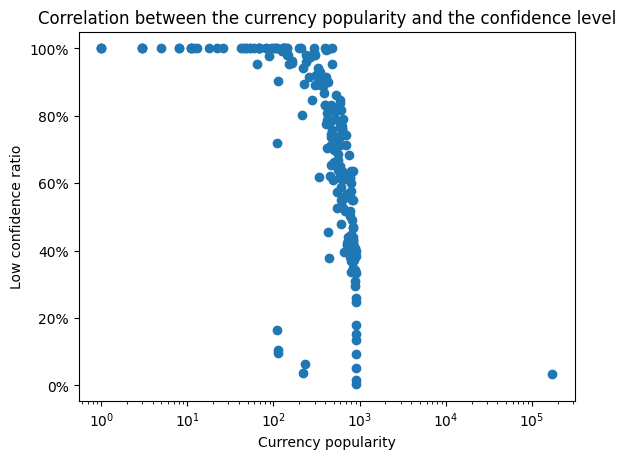

In [16]:
#Correlation between the currency popularity and the confidence level
plt.scatter(low_curr_distribution_analysis["total_currency_counts"],low_curr_distribution_analysis["low_confidence_ratio"])
plt.xlabel("Currency popularity")
plt.xscale("log")
plt.ylabel("Low confidence ratio")
plt.gca().yaxis.set_major_formatter(PercentFormatter(100))
plt.title("Correlation between the currency popularity and the confidence level")
plt.show()

**Conclusion:** The correlation analysis indicates a moderate negative relationship (r = -0.60) between currency popularity and the ratio of low-confidence observations, suggesting that more frequently traded currencies tend to have more reliable exchange rate estimates, although other factors may also influence the confidence level. Nevertheless, the analysis shows that low-confidence observations are common across most currencies in the dataset. Only 8 out of 233 currencies have a proportion of low-confidence values below 10%, with the lowest ratios observed for the main trading currencies such as **Chaos Orb**, **Divine Orb**, and **Mirror of Kalandra**. As these currencies dominate the market and represent the majority of transactions, the small proportion of low-confidence observations (<3.5%) indicates that removing such values is unlikely to significantly affect the overall analysis. Therefore, low-confidence observations may be excluded from the **Currency dataset**.

In [17]:
#Filtering low confidence values
currency_processed1= merged_currency_raw[merged_currency_raw["Confidence"] != "Low"]
currency_processed1

,League,Date,Get,Pay,Value,Confidence
0,Keepers,2025-10-31,Chromatic Orb,Chaos Orb,0.20000,High
1,Keepers,2025-11-01,Chromatic Orb,Chaos Orb,0.19231,High
2,Keepers,2025-11-02,Chromatic Orb,Chaos Orb,0.19231,High
3,Keepers,2025-11-03,Chromatic Orb,Chaos Orb,0.16667,High
4,Keepers,2025-11-04,Chromatic Orb,Chaos Orb,0.14970,High
...,...,...,...,...,...,...
37027,Ancestor,2023-12-01,Kirac's Memory,Chaos Orb,10.00000,High
37028,Ancestor,2023-12-02,Kirac's Memory,Chaos Orb,10.00000,High
37029,Ancestor,2023-12-03,Kirac's Memory,Chaos Orb,10.00000,High
37030,Ancestor,2023-12-04,Kirac's Memory,Chaos Orb,10.00000,High


### 5. Filtering Specific Records from the Dataset

As mentioned earlier, based on the knowledge of the game and the functioning of the trading market, it was decided to filter additional records from the dataset. Only the most commonly used trading currencies were retained in the **Pay column**, namely **Chaos Orb, Divine Orb, Exalted Orb** and **Mirror of Kalandra**.

In [18]:
#Filtering records based on main trading currencies in the Pay column
currency_processed2= currency_processed1[currency_processed1["Pay"].isin(["Chaos Orb","Exalted Orb","Divine Orb","Mirror of Kalandra"])]
currency_processed2

,League,Date,Get,Pay,Value,Confidence
0,Keepers,2025-10-31,Chromatic Orb,Chaos Orb,0.20000,High
1,Keepers,2025-11-01,Chromatic Orb,Chaos Orb,0.19231,High
2,Keepers,2025-11-02,Chromatic Orb,Chaos Orb,0.19231,High
3,Keepers,2025-11-03,Chromatic Orb,Chaos Orb,0.16667,High
4,Keepers,2025-11-04,Chromatic Orb,Chaos Orb,0.14970,High
...,...,...,...,...,...,...
37027,Ancestor,2023-12-01,Kirac's Memory,Chaos Orb,10.00000,High
37028,Ancestor,2023-12-02,Kirac's Memory,Chaos Orb,10.00000,High
37029,Ancestor,2023-12-03,Kirac's Memory,Chaos Orb,10.00000,High
37030,Ancestor,2023-12-04,Kirac's Memory,Chaos Orb,10.00000,High


The next step was to verify whether any records with **Value = 0** are present in the dataset. Since a zero exchange value does not represent a meaningful transaction in the context of the in-game economy, such records would not provide any analytical value and were therefore removed from the dataset.

In [19]:
currency_processed2[(currency_processed2.Value==0)]

,League,Date,Get,Pay,Value,Confidence
12561,Keepers,2026-02-26,Chaos Orb,Mirror of Kalandra,0.0,High
12562,Keepers,2026-02-27,Chaos Orb,Mirror of Kalandra,0.0,High
12563,Keepers,2026-02-28,Chaos Orb,Mirror of Kalandra,0.0,High
12564,Keepers,2026-03-01,Chaos Orb,Mirror of Kalandra,0.0,High
12565,Keepers,2026-03-02,Chaos Orb,Mirror of Kalandra,0.0,High
...,...,...,...,...,...,...
18297,Affliction,2024-01-24,Chaos Orb,Mirror of Kalandra,0.0,High
18298,Affliction,2024-01-25,Chaos Orb,Mirror of Kalandra,0.0,High
18299,Affliction,2024-01-26,Chaos Orb,Mirror of Kalandra,0.0,High
18300,Affliction,2024-01-27,Chaos Orb,Mirror of Kalandra,0.0,High


In [20]:
#Filtering 0-Value Records
currency_processed3 = currency_processed2[currency_processed2.Value!=0]
currency_processed3

,League,Date,Get,Pay,Value,Confidence
0,Keepers,2025-10-31,Chromatic Orb,Chaos Orb,0.20000,High
1,Keepers,2025-11-01,Chromatic Orb,Chaos Orb,0.19231,High
2,Keepers,2025-11-02,Chromatic Orb,Chaos Orb,0.19231,High
3,Keepers,2025-11-03,Chromatic Orb,Chaos Orb,0.16667,High
4,Keepers,2025-11-04,Chromatic Orb,Chaos Orb,0.14970,High
...,...,...,...,...,...,...
37027,Ancestor,2023-12-01,Kirac's Memory,Chaos Orb,10.00000,High
37028,Ancestor,2023-12-02,Kirac's Memory,Chaos Orb,10.00000,High
37029,Ancestor,2023-12-03,Kirac's Memory,Chaos Orb,10.00000,High
37030,Ancestor,2023-12-04,Kirac's Memory,Chaos Orb,10.00000,High


### 6. Exporting cleaned data

In [45]:
currency_processed3.reset_index(drop=True).to_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/currency_data_processed/currency_processed.csv",sep=";",index=False)

## Items Dataset

### 1. Merging datasets from different leagues

In [22]:
merged_items_raw= pd.concat([keepers_items_raw, mercenaries_items_raw, settlers_items_raw, necropolis_items_raw, affliction_items_raw, ancestor_items_raw])
show(merged_items_raw)

Loading ITables v2.7.0 from the internet... (need help?)


### 2. Removing non-significant columns
The **Id** and the **Base type** column is irrelevant for the planned analysis and therefore it was excluded. The **Variant** column applies only to a small number of very specific items in the game so this variable was also excluded from the further analysis.


In [23]:
items_processed1 = merged_items_raw.drop(columns=['Id','Variant','BaseType'])
items_processed1

,League,Date,Type,Name,Links,Value,Confidence
0,Keepers,2025-10-31,UniqueWeapon,Redbeak,1-4 links,0.935,High
1,Keepers,2025-11-01,UniqueWeapon,Redbeak,1-4 links,0.300,High
2,Keepers,2025-11-02,UniqueWeapon,Redbeak,1-4 links,0.120,High
3,Keepers,2025-11-03,UniqueWeapon,Redbeak,1-4 links,0.180,High
4,Keepers,2025-11-04,UniqueWeapon,Redbeak,1-4 links,1.000,High
...,...,...,...,...,...,...,...
3975861,Ancestor,2023-12-04,BaseType,Compound Spiked Shield,NaN,5196.400,Low
3975862,Ancestor,2023-12-05,BaseType,Compound Spiked Shield,NaN,5196.400,Low
3975863,Ancestor,2023-12-05,BaseType,Tornado Wand,NaN,249.000,Low
3975864,Ancestor,2023-12-05,BaseType,Oiled Vest,NaN,20.000,Low


### 3. Handling Missing Values

In [24]:
# Number of missing values in the items dataset after dropping the Id, Variant and Base type columns
items_processed1.isna().sum()

League               0
Date               474
Type               474
Name               914
Links         25990513
Value             1422
Confidence        1422
dtype: int64

#### >> **Links** column missing values

Most missing values are present in **Links** column.

In [25]:
show(items_processed1.groupby(['Type', 'Name', 'Links']).size().reset_index(name='count'))

Loading ITables v2.7.0 from the internet... (need help?)


In Path of Exile, only equipment items can have socket links, with the exception of **rings**, **amulets**, and **belts**. Most items can have between **1 and 4 links**, while **body armour** and **two-handed weapons** can have up to **6 links**. In general, the higher the number of links, the more valuable the item.
However, analysis of the dataset showed above indicates that for items capable of having more than four links, the data include both the base versions (1–4 links) and the upgraded versions with 5 or 6 links. Since the goal of the analysis is to compare item prices across leagues and over time, it is sufficient to analyse the base versions of items (1–4 links), which can later be upgraded to higher link counts in gameplay.

This approach ensures that price comparisons are made between comparable base item versions, avoiding distortions caused by upgrades that significantly increase item value.

Therefore, records with more than 4 links were filtered out. After this filtering step, the remaining observations represent base item versions. As a result, the **Links** column no longer provides additional analytical value and can be safely removed, which also eliminates the missing values previously present in this column.

In [26]:
# Filtering records with 5 and 6 links (keeping only base versions)
items_processed2 = items_processed1[~items_processed1["Links"].isin(["5 links", "6 links"])]
items_processed2

,League,Date,Type,Name,Links,Value,Confidence
0,Keepers,2025-10-31,UniqueWeapon,Redbeak,1-4 links,0.935,High
1,Keepers,2025-11-01,UniqueWeapon,Redbeak,1-4 links,0.300,High
2,Keepers,2025-11-02,UniqueWeapon,Redbeak,1-4 links,0.120,High
3,Keepers,2025-11-03,UniqueWeapon,Redbeak,1-4 links,0.180,High
4,Keepers,2025-11-04,UniqueWeapon,Redbeak,1-4 links,1.000,High
...,...,...,...,...,...,...,...
3975861,Ancestor,2023-12-04,BaseType,Compound Spiked Shield,NaN,5196.400,Low
3975862,Ancestor,2023-12-05,BaseType,Compound Spiked Shield,NaN,5196.400,Low
3975863,Ancestor,2023-12-05,BaseType,Tornado Wand,NaN,249.000,Low
3975864,Ancestor,2023-12-05,BaseType,Oiled Vest,NaN,20.000,Low


In [27]:
# Removing Links column
items_processed3 = items_processed2.drop(columns=["Links"])
items_processed3

,League,Date,Type,Name,Value,Confidence
0,Keepers,2025-10-31,UniqueWeapon,Redbeak,0.935,High
1,Keepers,2025-11-01,UniqueWeapon,Redbeak,0.300,High
2,Keepers,2025-11-02,UniqueWeapon,Redbeak,0.120,High
3,Keepers,2025-11-03,UniqueWeapon,Redbeak,0.180,High
4,Keepers,2025-11-04,UniqueWeapon,Redbeak,1.000,High
...,...,...,...,...,...,...
3975861,Ancestor,2023-12-04,BaseType,Compound Spiked Shield,5196.400,Low
3975862,Ancestor,2023-12-05,BaseType,Compound Spiked Shield,5196.400,Low
3975863,Ancestor,2023-12-05,BaseType,Tornado Wand,249.000,Low
3975864,Ancestor,2023-12-05,BaseType,Oiled Vest,20.000,Low


#### >> Other columns missing values

In [28]:
# Number of missing values in the Items dataset after dropping Links column
items_processed3.isna().sum()

League           0
Date           474
Type           474
Name           914
Value         1422
Confidence    1422
dtype: int64

In [29]:
#visualisation of the NaN values in order to analyse the missing data 
show(items_processed3[items_processed3.isna().any(axis=1)])

Loading ITables v2.7.0 from the internet... (need help?)


From the analysis above, it can be observed that there are unusual item **Types** and **League names** that do not actually exist. These entries indicate errors in the dataset and therefore must be removed before further analysis.

In [30]:
# Types of items with missing values
types_with_missing_values = items_processed3[items_processed3["Value"].isna()]["Type"].unique()
types_with_missing_values

array(['Coffin', nan, '5', '3', '2', '3.435', '3.18', '2.1', '1.9', '1.8',
       '1.7', '2.8', '21', '1', '0.78', '0.9', '3.6', '3.4', '3.2', '10',
       '4.6', '2.15', '1.575', '1.6', '1.2', '2.025', '1.4', '1.1',
       '1.77', '2.7', '2.2', '5.8', '4.2', '4.4', '2.6', '4.99', '1.5',
       '1.32', '1.28', '1.33', '1.79', '2.05', '2.5', '2.3', '1.82',
       '1.3', '0.84', '1.47', '1.35', '1.09', '1.25', '1.18', '1.17',
       '1.38', '1.49', '1.48', '0.43', '3.1', '9.4', '6.5', '8.88',
       '9.12', '9.62', '9.2', '8', '6.8', '5.2', '4.9', '4', '5.5',
       '7.11', '6.48', '3.93', '3.88', '3.86', '3.3', '5.98', '5.95',
       '3.8', '5.7', '5.6', '4.7', '4.3', '6', '5.26', '5.25', '3.7',
       '14', '7', '12', '26', '80'], dtype=object)

None of these numerical results represent valid item types. In addition, coffins are not standard items in the game; they were only introduced temporarily during a single league.

In [31]:
#Removing data errors from Type column - coffin and all numerical names

mask_remove = items_processed3["Type"].isin(types_with_missing_values)
mask_nan = items_processed3["Type"].isna()

items_processed4 = items_processed3[~mask_remove | mask_nan]

In [32]:
#Removing data errors from League column - coffin and all numerical names
leagues_names=["Keepers","Mercenaries","Settlers","Necropolis","Affliction","Ancestor"]
items_processed5 = items_processed4[items_processed4["League"].isin(leagues_names)].copy()

In [33]:
# Number of missing values in the Items dataset after excluding additional records
items_processed5.isna().sum()

League         0
Date           0
Type           0
Name          15
Value          0
Confidence     0
dtype: int64

In [34]:
#visualisation of the remaining NaN values 
items_processed5[items_processed5.isna().any(axis=1)]

,League,Date,Type,Name,Value,Confidence
3655492,Ancestor,2023-08-30,UniqueRelic,NaN,39.4,High
3655493,Ancestor,2023-08-31,UniqueRelic,NaN,43.0,High
3655494,Ancestor,2023-09-01,UniqueRelic,NaN,50.0,High
3655495,Ancestor,2023-09-02,UniqueRelic,NaN,50.0,High
3655496,Ancestor,2023-09-03,UniqueRelic,NaN,50.0,High
3655497,Ancestor,2023-09-04,UniqueRelic,NaN,37.1,High
3655498,Ancestor,2023-09-05,UniqueRelic,NaN,37.1,High
3655499,Ancestor,2023-09-06,UniqueRelic,NaN,35.2,High
3655500,Ancestor,2023-09-07,UniqueRelic,NaN,33.3,High
3655501,Ancestor,2023-09-08,UniqueRelic,NaN,33.3,High


Records shown above contain only a generic item type but lack a specific item name, which makes it impossible to uniquely identify the item being referenced. Without a clear item identifier, the corresponding price cannot be reliably associated with a particular object in the game economy. Furthermore, these entries appear only in a single league and therefore represent temporary or league-specific mechanics rather than standard items that exist across multiple leagues. Since the goal of this analysis is to study the broader item economy of the game, such non-standard and non-identifiable entries could be excluded from further analysis.

In [35]:
# Removing remaining missing values 
items_processed5 = items_processed5.dropna()

### 4. Removing low confidence values
Another possible approach would be to remove observations with **low and/or medium** confidence, since these values are based on only a few observations and may therefore be statistically inaccurate. However, the initial exploratory data analysis indicates that low-confidence values constitute approximately 38% of the dataset. For this reason, this aspect requires further analysis before deciding whether these observations could be excluded and to what extent.


#####   >> Distribution of **low and medium confidence** observations by items

In [36]:
#Distribution of low and medium confidence values by items

show(items_processed5.groupby(['Name', 'Confidence']).size().reset_index(name='count'))

Loading ITables v2.7.0 from the internet... (need help?)


In [37]:
#Confidence values by items with low+medium confidence percentage
items_processed6 = (items_processed5.groupby(["Name", "Confidence"]).size().unstack(fill_value=0))
items_processed6["Low+Medium Percentage"] = (items_processed6.get("Low", 0) + items_processed6.get("Medium", 0)) / items_processed6.sum(axis=1) * 100

show(items_processed6.sort_values("Low+Medium Percentage", ascending=False))

Loading ITables v2.7.0 from the internet... (need help?)


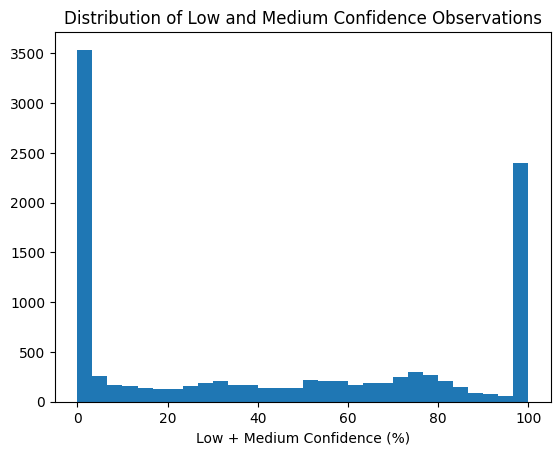

In [38]:
plt.hist(items_processed6["Low+Medium Percentage"], bins=30)
plt.xlabel("Low + Medium Confidence (%)")
plt.title("Distribution of Low and Medium Confidence Observations")
plt.show()

In [39]:
#Number of items for which low+medium confidence values are 20% or higher
len(items_processed6[items_processed6["Low+Medium Percentage"] >= 20])

6413

In [40]:
#Ratio of items for which low+medium confidence values are  20% or higher
len(items_processed6[items_processed6["Low+Medium Percentage"] >= 20])/len(items_processed6)

0.5939612855422802

**Conclusion:** The histogram shows the distribution of the proportion of **Low and Medium confidence** observations across items in the dataset. While some items have a relatively small share of lower-confidence observations, a substantial number of items exhibit a higher proportion of Low and Medium confidence values. In fact, 6501 items (approximately 59% of the dataset) have 20% or more observations with Low or Medium confidence.

This indicates that lower-confidence observations are a common characteristic of the items market data, likely reflecting the varying frequency with which different items appear in the market. For many items, especially those traded less frequently, price estimates may be available only with Low or Medium confidence.

Removing such observations would therefore eliminate a large portion of the dataset and could lead to a significant loss of price information as well as introduce bias into the analysis. For this reason, all confidence levels were retained for the item price analysis.

### 5. Filtering Specific Records from the Dataset

#### >> Filtering 0-value records
The next step was to verify whether any records with **Value = 0** are present in the dataset. Since a zero exchange value does not represent a meaningful transaction in the context of the in-game economy, such records would not provide any analytical value and were therefore removed from the dataset.

In [41]:
(items_processed5["Value"] == 0).any()

True

In [42]:
# Filtering records with zero value
items_processed7 = items_processed5[items_processed5["Value"] != 0]

### 6. Exporting cleaned data

In [47]:
items_processed7.reset_index(drop=True).to_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/items_data_processed/items_processed.csv",sep=";",index=False)